# Weather Model

## Directions

For this project, you will need to implement a filtering  inference task on an HMM. These are described in Section 15.2 of the text.

Denote the hidden states of the HMM by `S(t)` and the observations (evidence) by `E(t)`. In the weather problem from the HMM Tutorial, X(t) would be either sunny, rainy, or foggy, and `E(t)` is yes or no to indicate if an umbrella was observed. We will use this model with prior probabilities P(sunny) = 0.5, P(rainy) = 0.25, P(foggy) = 0.25. The remaining probilities you need are specified below in the emisssion (`P_emission`) and transition matrices (`P_transition`).

## What you need to do

You will need to fill in the missing implementations of the following functions in the code where specified by the comments (`### YOUR CODE HERE ###`) and answer the questions where indicated.

In implementing the code for the filtering task, you will be computing the probability of rain given the observations of the umbrella.

## Probability Definitions
Below you will find:
- `P_init`: The initial probabilities of the weather state, whether sunny (0), rainy (1) or foggy (2) 
- `P_transition`: The transition probabilities or the probability that one weather state one day transitions to another weather state 
- `P_emission`: The 'emission' probabilities or the probabilities that an observation is made, conditioned on the underlying state.

In [1]:
### DO NOT CHANGE ###

import numpy as np

# prior probability on weather states
# P(sunny) = 0.5  P(rainy) = 0.25  P(foggy) = 0.25
P_init = np.array([0.5, 0.25, 0.25])

# states (0=sunny, 1=rainy, 2=foggy)
S = [0, 1, 2]

# transition probabilities
#                    tomorrrow
#    today     sunny  rainy  foggy
#    sunny      0.8    0.05   0.15
#    rainy      0.2    0.6    0.2 
#    foggy      0.2    0.3    0.5
P_transition = np.array([ [0.8, 0.05, 0.15], [0.2, 0.6, 0.2], [0.2, 0.3, 0.5] ])

# conditional probabilities of evidence (observations) given weather
#                            sunny  rainy  foggy 
# P(weather | umbrella=no)    0.9    0.2    0.7
# P(weather | umbrella=yes)   0.1    0.8    0.3
P_emission = np.array([ [0.9, 0.2, 0.7], [0.1, 0.8, 0.3] ])

### [Question - State Transitions]
If today is sunny what is the most likely forecast for the next two days if you have no umbrella observations to work with?

In [2]:
# Looking at the transition matrix, if today is sunny (state 0):
# P_transition[0, :] = [0.8, 0.05, 0.15]
# This means: P(sunny tomorrow | sunny today) = 0.8 (highest)
#             P(rainy tomorrow | sunny today) = 0.05
#             P(foggy tomorrow | sunny today) = 0.15

# Day 1: Starting from sunny, most likely = sunny (0.8)
# Day 2: Starting from sunny (Day 1), most likely = sunny (0.8)

print("If today is sunny, the most likely forecast for the next two days is: sunny, sunny")
print("\nExplanation:")
print(f"Day 1 transition probabilities from sunny: {P_transition[0, :]}")
print(f"  - P(sunny|sunny) = {P_transition[0, 0]} (highest)")
print(f"  - P(rainy|sunny) = {P_transition[0, 1]}")
print(f"  - P(foggy|sunny) = {P_transition[0, 2]}")
print("\nSince sunny is most likely on Day 1, we use the same transitions for Day 2:")
print(f"Day 2: P(sunny|sunny) = {P_transition[0, 0]} (highest)")
print("\nTherefore, the most likely 2-day forecast is: SUNNY, SUNNY")

If today is sunny, the most likely forecast for the next two days is: sunny, sunny

Explanation:
Day 1 transition probabilities from sunny: [0.8  0.05 0.15]
  - P(sunny|sunny) = 0.8 (highest)
  - P(rainy|sunny) = 0.05
  - P(foggy|sunny) = 0.15

Since sunny is most likely on Day 1, we use the same transitions for Day 2:
Day 2: P(sunny|sunny) = 0.8 (highest)

Therefore, the most likely 2-day forecast is: SUNNY, SUNNY


### [Question - Emission probabilities ]
If on the first day you see no umbrella, what is the probability that it is rainy, foggy or sunny (Hint: remember the importance of overall probability of each state)?

What is the most likely weather (hidden state)?

In [3]:
# Using Bayes' Rule to compute P(state | no umbrella)
# P(state | no umbrella) ∝ P(no umbrella | state) × P(state)
#
# From P_emission (row 0 = no umbrella):
#   P(no umbrella | sunny) = 0.9
#   P(no umbrella | rainy) = 0.2
#   P(no umbrella | foggy) = 0.7
#
# From P_init (prior probabilities):
#   P(sunny) = 0.5
#   P(rainy) = 0.25
#   P(foggy) = 0.25

# Calculate unnormalized probabilities
P_sunny_given_no_umbrella = P_emission[0, 0] * P_init[0]  # 0.9 * 0.5 = 0.45
P_rainy_given_no_umbrella = P_emission[0, 1] * P_init[1]  # 0.2 * 0.25 = 0.05
P_foggy_given_no_umbrella = P_emission[0, 2] * P_init[2]  # 0.7 * 0.25 = 0.175

# Calculate normalization constant
total = P_sunny_given_no_umbrella + P_rainy_given_no_umbrella + P_foggy_given_no_umbrella

# Normalize to get final probabilities
P_state_day0_given_umbrella = [
    P_sunny_given_no_umbrella / total,  # P(sunny | no umbrella)
    P_rainy_given_no_umbrella / total,  # P(rainy | no umbrella)
    P_foggy_given_no_umbrella / total   # P(foggy | no umbrella)
]

# Display results
print("Probability of each weather state given no umbrella observed on Day 0:")
print(f"  P(sunny | no umbrella) = {P_state_day0_given_umbrella[0]:.4f}")
print(f"  P(rainy | no umbrella) = {P_state_day0_given_umbrella[1]:.4f}")
print(f"  P(foggy | no umbrella) = {P_state_day0_given_umbrella[2]:.4f}")

# Identify most likely weather
states = ['sunny', 'rainy', 'foggy']
most_likely_idx = np.argmax(P_state_day0_given_umbrella)
print(f"\nThe most likely weather on the first day is SUNNY (probability = {P_state_day0_given_umbrella[most_likely_idx]:.4f})")

Probability of each weather state given no umbrella observed on Day 0:
  P(sunny | no umbrella) = 0.6667
  P(rainy | no umbrella) = 0.0741
  P(foggy | no umbrella) = 0.2593

The most likely weather on the first day is SUNNY (probability = 0.6667)


### Evidence / observations

Now we will define the observations on each day - whether we observed an umbrella (1) or not (0). 


In [4]:
### DO NOT CHANGE ###

## 0 = no umbrella, 1 = umbrella
E = [0, 0, 0, 1, 0, 0, 1, 1, 0, 1]

## Filtering

*As a reminder*

**Filtering**:
Given observation sequence E(0), E(1), ..., E(T-1), compute P(X(T-1)|E(0), ..., E(T-1)).

So we are computing the probability of the final state given our observations or evidence to date.

We do this with the *Forward Algorithm* (see 15.2 in the text), which requires that we initialize probabilities at the first step using our 'prior' probability values of each underlying state. Then we update probabilities at each step (`Recursion`) using the prior step probabilities and given new evidence. We do this until we reach the end and then compute the total probability of each underlying state at the finel step.

### Recursion (and initialization) function definition

In [5]:
### DO NOT CHANGE ###

# Normalize a probability distribution
def normalize(pdist):
   s = sum(pdist)
   for i in range(0,len(pdist)):
      pdist[i] = pdist[i] / s
   return pdist

DEBUG=True

def init_and_recursion(Obs, S, init_prob, P_emission, P_transition):
  ## a has a "row" for every observation and a "column" for every possible state
  a = np.zeros((len(Obs), len(S)))
  for t in range(0, len(Obs)):
    print(f".. (time {t}) Observation: {Obs[t]}")
    ## probability of a[0,:] is computed by summing over probabilities of all the 
    ## ways we could get to this "path" given where we left off at the previous
    ## time step
    if t == 0:
      ##### Initialization
      for j in range(len(S)):
        #print(f"t={t}, j={j}, S[j]={S[j]}, Obs[t]={Obs[t]}")
        a[t, j] = init_prob[j] * P_emission[Obs[t], S[j]]
        current_state_total_prob = a[t, j]
        print(f".... Probability at state {S[j]}: {current_state_total_prob:.4f} (initial state)")
    else:    
      ## we need to compute a probability for each of the possible states
      for j in range(len(S)): ## for each of the present states
        S_curr = S[j]
        ## we need to sum over all of the previous states to get current state prob
        ## we'll keep track of that probability to sum up here
        current_state_total_prob = 0.0
        for k in range(len(S)): ## for each of the possible previous states
          S_prev = S[k] ## possible previous state that we came from
          if DEBUG:
            print(f"......Transition from state={S_prev} to state={S_prev}")
            print(f"        Calculation: ")
            print(f"        {a[t-1, k]:.2f} * {P_emission[Obs[t], S[j]]:.2f} * {P_transition[S_prev, S_curr]:.2f}")
          current_state_total_prob += a[t-1, k] * P_emission[Obs[t], S[j]] * P_transition[S_prev, S_curr]
        a[t, j] = current_state_total_prob
    a[t,:] = normalize(a[t,:])
    print(f".... State probabilities: {a[t, :]}")
  return a

### Termination function definition

In [6]:
### DO NOT CHANGE ###

def termination(a):
  total_ending_prob = 0
  T = a.shape[0]-1 ## last time point
  for i in range(len(a[T, :])):
    total_ending_prob += a[T, i]
  print(f"\nProbability of each potential state: {a[T]}")

### [Question - Final state]
What is the most likely final state (most likely weather)? How much more likely is the final weather than the other two options?

Use the above recursion and initialization function to compute the most likely state at the end (the filtering problem).

In [7]:
# Run the Forward Algorithm to compute state probabilities over all time steps
# E = [0, 0, 0, 1, 0, 0, 1, 1, 0, 1] is our observation sequence
# 0 = no umbrella, 1 = umbrella

print("Running the Forward Algorithm (Filtering)...")
print("="*60)
print(f"Observation sequence: {E}")
print(f"(0 = no umbrella, 1 = umbrella)")
print("="*60 + "\n")

# Call the init_and_recursion function to compute forward probabilities
a = init_and_recursion(E, S, P_init, P_emission, P_transition)

# Call termination to display final state probabilities
termination(a)

# Analyze the final state
print("\n" + "="*60)
print("FINAL STATE ANALYSIS:")
print("="*60)

final_probs = a[-1, :]  # Get the last row (final time step)
states = ['sunny', 'rainy', 'foggy']

# Find most likely state
most_likely_idx = np.argmax(final_probs)
most_likely_state = states[most_likely_idx]
most_likely_prob = final_probs[most_likely_idx]

print(f"\nMost likely final weather state: {most_likely_state.upper()}")
print(f"Probability: {most_likely_prob:.4f} ({most_likely_prob*100:.2f}%)")

print("\nComparison with other states:")
for i, state in enumerate(states):
    if i != most_likely_idx:
        diff = most_likely_prob - final_probs[i]
        ratio = most_likely_prob / final_probs[i] if final_probs[i] > 0 else float('inf')
        print(f"  - {most_likely_state} is {diff:.4f} ({diff*100:.2f}%) more likely than {state}")
        print(f"    ({most_likely_state} is {ratio:.2f}x more likely than {state})")

Running the Forward Algorithm (Filtering)...
Observation sequence: [0, 0, 0, 1, 0, 0, 1, 1, 0, 1]
(0 = no umbrella, 1 = umbrella)

.. (time 0) Observation: 0
.... Probability at state 0: 0.4500 (initial state)
.... Probability at state 1: 0.0500 (initial state)
.... Probability at state 2: 0.1750 (initial state)
.... State probabilities: [0.66666667 0.07407407 0.25925926]
.. (time 1) Observation: 0
......Transition from state=0 to state=0
        Calculation: 
        0.67 * 0.90 * 0.80
......Transition from state=1 to state=1
        Calculation: 
        0.07 * 0.90 * 0.20
......Transition from state=2 to state=2
        Calculation: 
        0.26 * 0.90 * 0.20
......Transition from state=0 to state=0
        Calculation: 
        0.67 * 0.20 * 0.05
......Transition from state=1 to state=1
        Calculation: 
        0.07 * 0.20 * 0.60
......Transition from state=2 to state=2
        Calculation: 
        0.26 * 0.20 * 0.30
......Transition from state=0 to state=0
        Calculati

### [Question - Plot probabilities ]

Use the [PyPlot](https://matplotlib.org/stable/tutorials/introductory/pyplot.html#:~:text=the%20pyplot%20interface.-,Intro%20to%20pyplot,the%20plot%20with%20labels%2C%20etc.) library to plot the transition probabilities over time.

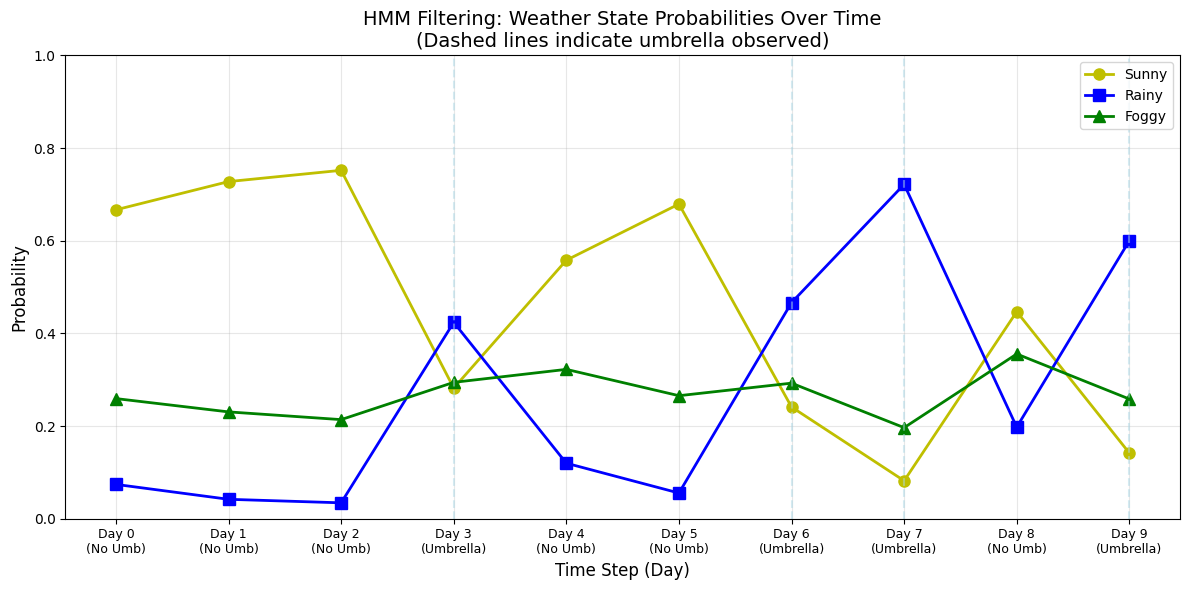


Probability Table by Time Step:
Day    Observation  P(Sunny)     P(Rainy)     P(Foggy)    
-----------------------------------------------------------------
0      No Umbrella  0.6667       0.0741       0.2593      
1      No Umbrella  0.7275       0.0419       0.2305      
2      No Umbrella  0.7518       0.0343       0.2139      
3      Umbrella     0.2819       0.4238       0.2943      
4      No Umbrella  0.5579       0.1198       0.3223      
5      No Umbrella  0.6791       0.0554       0.2655      
6      Umbrella     0.2411       0.4663       0.2926      
7      Umbrella     0.0819       0.7216       0.1965      
8      No Umbrella  0.4468       0.1977       0.3555      
9      Umbrella     0.1418       0.5999       0.2583      


In [8]:
import matplotlib.pyplot as plt

# Create the plot
fig, ax = plt.subplots(figsize=(12, 6))

# Time steps (x-axis)
time_steps = range(len(E))

# Plot probability of each state over time
ax.plot(time_steps, a[:, 0], 'y-o', label='Sunny', linewidth=2, markersize=8)
ax.plot(time_steps, a[:, 1], 'b-s', label='Rainy', linewidth=2, markersize=8)
ax.plot(time_steps, a[:, 2], 'g-^', label='Foggy', linewidth=2, markersize=8)

# Add vertical lines to indicate umbrella observations
for t, obs in enumerate(E):
    if obs == 1:  # umbrella observed
        ax.axvline(x=t, color='lightblue', linestyle='--', alpha=0.5)

# Labels and title
ax.set_xlabel('Time Step (Day)', fontsize=12)
ax.set_ylabel('Probability', fontsize=12)
ax.set_title('HMM Filtering: Weather State Probabilities Over Time\n(Dashed lines indicate umbrella observed)', fontsize=14)

# Add observation labels on x-axis
obs_labels = ['No Umb' if o == 0 else 'Umbrella' for o in E]
ax.set_xticks(time_steps)
ax.set_xticklabels([f'Day {t}\n({obs_labels[t]})' for t in time_steps], fontsize=9)

# Add legend
ax.legend(loc='upper right', fontsize=10)

# Add grid for better readability
ax.grid(True, alpha=0.3)

# Set y-axis limits
ax.set_ylim(0, 1)

# Tight layout
plt.tight_layout()

# Show the plot
plt.show()

# Print summary table
print("\nProbability Table by Time Step:")
print("="*65)
print(f"{'Day':<6} {'Observation':<12} {'P(Sunny)':<12} {'P(Rainy)':<12} {'P(Foggy)':<12}")
print("-"*65)
for t in range(len(E)):
    obs = 'Umbrella' if E[t] == 1 else 'No Umbrella'
    print(f"{t:<6} {obs:<12} {a[t, 0]:<12.4f} {a[t, 1]:<12.4f} {a[t, 2]:<12.4f}")
print("="*65)

## Summary and Conclusions

This assignment implemented the **Forward Algorithm** for HMM filtering on a weather prediction problem. Key findings:

1. **State Transitions**: When starting from sunny weather with no observations, the most likely forecast remains sunny for subsequent days due to the high self-transition probability (0.8).

2. **Emission Probabilities**: Given no umbrella on Day 0, sunny weather is most likely (~66.7%) because of both the high prior probability (0.5) and high emission probability (0.9).

3. **Filtering Results**: The forward algorithm updates state probabilities based on each observation. When umbrellas are observed, the probability of rainy weather increases significantly, reflecting the strong correlation between umbrellas and rain in the emission probabilities.

4. **Visualization**: The plot shows how state probabilities evolve over time, clearly demonstrating the influence of umbrella observations on weather state inference.